In [1]:
import pandas as pd

In [2]:
train = pd.read_csv("C:/Users/RGUKT/Desktop/mobile_price_prediction/data/train.csv")
test = pd.read_csv("C:/Users/RGUKT/Desktop/mobile_price_prediction/data/test.csv")

print("Training Dataset Loaded Successfully")
print("Testing Dataset Loaded Successfully")

Training Dataset Loaded Successfully
Testing Dataset Loaded Successfully


In [6]:
#Select Important Features
important_features = [
    "ram",
    "battery_power",
    "fc",
    "pc",
    "n_cores",
    "clock_speed"
]

train[important_features].head()

,ram,battery_power,fc,pc,n_cores,clock_speed
0,2549,842,1,2,2,2.2
1,2631,1021,0,6,3,0.5
2,2603,563,2,6,5,0.5
3,2769,615,0,9,6,2.5
4,1411,1821,13,14,2,1.2


In [7]:
#Create New Feature: Total Camera
train["total_camera_mp"] = train["fc"] + train["pc"]
test["total_camera_mp"] = test["fc"] + test["pc"]

train[["fc", "pc", "total_camera_mp"]].head()

,fc,pc,total_camera_mp
0,1,2,3
1,0,6,6
2,2,6,8
3,0,9,9
4,13,14,27


In [8]:
#Create New Feature: Processor Score
train["processor_score"] = train["n_cores"] * train["clock_speed"]
test["processor_score"] = test["n_cores"] * test["clock_speed"]

train[["n_cores", "clock_speed", "processor_score"]].head()

,n_cores,clock_speed,processor_score
0,2,2.2,4.4
1,3,0.5,1.5
2,5,0.5,2.5
3,6,2.5,15.0
4,2,1.2,2.4


In [9]:
#Check New Features
new_features = [
    "total_camera_mp",
    "processor_score"
]

print("New Feature Summary:")
print(train[new_features].describe())

New Feature Summary:
       total_camera_mp  processor_score
count      2000.000000      2000.000000
mean         14.226000         6.870650
std           9.463916         5.393003
min           0.000000         0.500000
25%           7.000000         2.500000
50%          14.000000         5.100000
75%          21.000000        10.250000
max          39.000000        24.000000


In [10]:
#Correlation Analysis
correlation = train.corr(numeric_only=True)

print(
    correlation["price_range"]
    .sort_values(ascending=False)
)

price_range        1.000000
ram                0.917046
battery_power      0.200723
px_width           0.165818
px_height          0.148858
int_memory         0.044435
sc_w               0.038711
pc                 0.033599
total_camera_mp    0.031621
three_g            0.023611
sc_h               0.022986
fc                 0.021998
talk_time          0.021859
blue               0.020573
wifi               0.018785
dual_sim           0.017444
four_g             0.014772
n_cores            0.004399
m_dep              0.000853
clock_speed       -0.006606
processor_score   -0.008290
mobile_wt         -0.030302
touch_screen      -0.030411
Name: price_range, dtype: float64


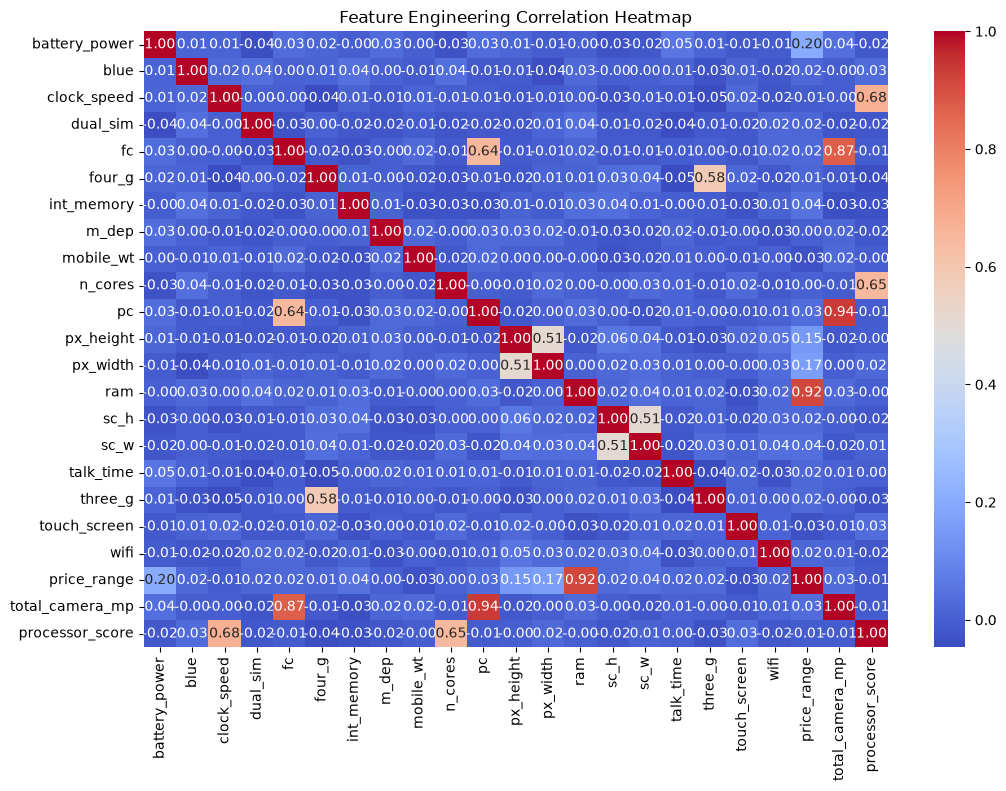

In [11]:
#Correlation Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Engineering Correlation Heatmap")
plt.show()

In [12]:
#Statistical Hypothesis Testing
from scipy.stats import f_oneway

ram_group_0 = train[train["price_range"] == 0]["ram"]
ram_group_1 = train[train["price_range"] == 1]["ram"]
ram_group_2 = train[train["price_range"] == 2]["ram"]
ram_group_3 = train[train["price_range"] == 3]["ram"]

f_stat, p_value = f_oneway(
    ram_group_0,
    ram_group_1,
    ram_group_2,
    ram_group_3
)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Average RAM differs across price ranges.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant difference found.")

F-Statistic: 3520.1108238957563
P-Value: 0.0
Reject Null Hypothesis
Average RAM differs across price ranges.


In [13]:
#Compare Average RAM Across Price Ranges
ram_comparison = train.groupby("price_range")["ram"].mean()

print("Average RAM for Each Price Range:")
print(ram_comparison)

Average RAM for Each Price Range:
price_range
0     785.314
1    1679.490
2    2582.816
3    3449.232
Name: ram, dtype: float64


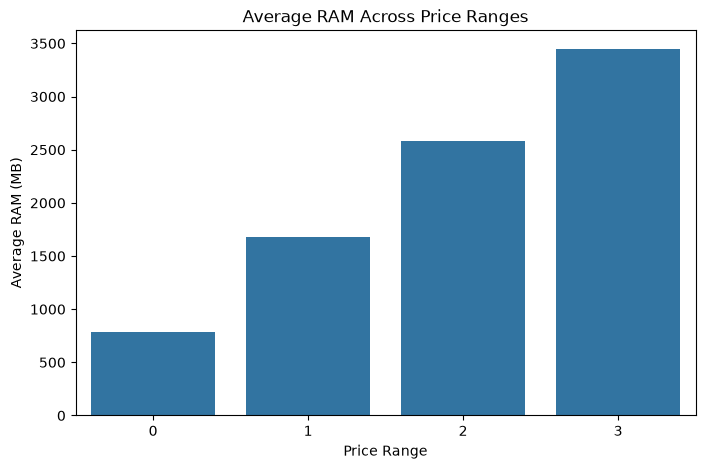

In [14]:
#Visualize Average RAM
plt.figure(figsize=(8, 5))

sns.barplot(
    x=ram_comparison.index,
    y=ram_comparison.values
)

plt.title("Average RAM Across Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Average RAM (MB)")
plt.show()

In [15]:
#Select Final Features
final_features = [
    "ram",
    "battery_power",
    "total_camera_mp",
    "processor_score"
]

X = train[final_features]
y = train["price_range"]

X_test = test[final_features]

print("Selected Features:")
print(final_features)

print("\nTraining Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Testing Features Shape:", X_test.shape)

Selected Features:
['ram', 'battery_power', 'total_camera_mp', 'processor_score']

Training Features Shape: (2000, 4)
Target Shape: (2000,)
Testing Features Shape: (1000, 4)


In [16]:
#Check Final Dataset
print("Training Data:")
display(X.head())

print("Testing Data:")
display(X_test.head())

Training Data:


,ram,battery_power,total_camera_mp,processor_score
0,2549,842,3,4.4
1,2631,1021,6,1.5
2,2603,563,8,2.5
3,2769,615,9,15.0
4,1411,1821,27,2.4


Testing Data:


,ram,battery_power,total_camera_mp,processor_score
0,3476,1043,30,5.4
1,3895,841,16,2.5
2,2396,1807,5,8.4
3,3893,1546,38,4.0
4,1773,1434,29,8.4


In [17]:
#Check Missing Values After Feature Engineering
print("Training Missing Values:")
print(X.isnull().sum())

print("\nTesting Missing Values:")
print(X_test.isnull().sum())

Training Missing Values:
ram                0
battery_power      0
total_camera_mp    0
processor_score    0
dtype: int64

Testing Missing Values:
ram                0
battery_power      0
total_camera_mp    0
processor_score    0
dtype: int64


In [18]:
#Save Feature-Engineered Datasets
train_processed = X.copy()
train_processed["price_range"] = y

test_processed = X_test.copy()

train_processed.to_csv(
    "../data/train_feature_engineered.csv",
    index=False
)

test_processed.to_csv(
    "../data/test_feature_engineered.csv",
    index=False
)

print("Feature-Engineered Datasets Saved Successfully!")

Feature-Engineered Datasets Saved Successfully!
